In [1]:
import numpy as np 
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression

In [2]:
bias = 200
X, y, coef = make_regression(n_features=1, bias=bias ,random_state=42, coef=True, noise=10)

In [3]:
coef

array(41.74110031)

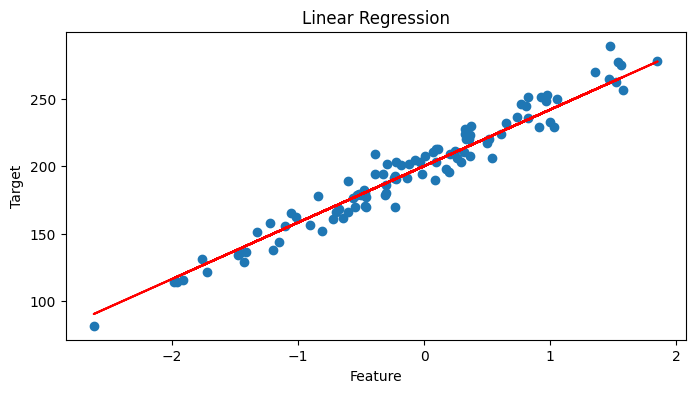

In [4]:
plt.figure(figsize=(8, 4))
plt.scatter(X, y)
plt.plot(X, coef * X + bias, color='red')
plt.xlabel('Feature')
plt.ylabel('Target')
plt.title('Linear Regression')
plt.show()

# Scikit Implementation

In [5]:
from sklearn.linear_model import LinearRegression as Sk_LinearRegression

model = Sk_LinearRegression()
model.fit(X, y)

print(f"beta: {model.coef_[0]:.3f}, b: {model.intercept_:.3f}")

beta: 44.437, b: 201.165


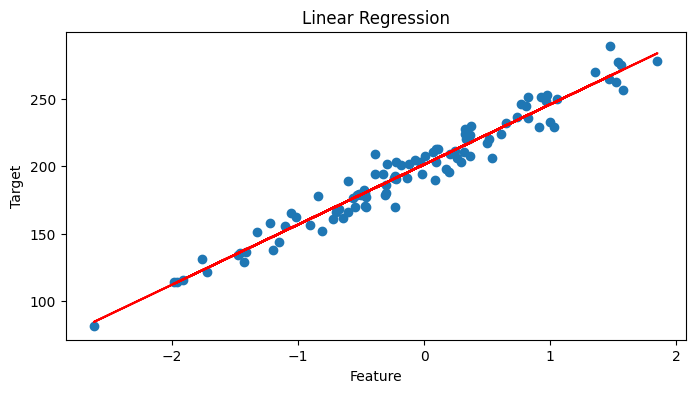

In [6]:
plt.figure(figsize=(8, 4))
plt.scatter(X, y)
plt.plot(X, model.coef_[0] * X + model.intercept_, color='red')
plt.xlabel('Feature')
plt.ylabel('Target')
plt.title('Linear Regression')
plt.show()

# Gradient Descent Implementation

In [7]:
from sklearn.preprocessing import StandardScaler
from linear_regression import LinearRegression

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

model = LinearRegression()
model.fit(X_scaled, y, verbose=1, lr=5e-3, max_iter=10000)

0 Iteration | Loss: 19760.816250654967
100 Iteration | Loss: 2681.346019854941
200 Iteration | Loss: 393.04415158611386
300 Iteration | Loss: 86.45821129859074
400 Iteration | Loss: 45.38192670284616
500 Iteration | Loss: 39.878539448334934
600 Iteration | Loss: 39.14119741335802
700 Iteration | Loss: 39.04240856725275
800 Iteration | Loss: 39.029172869771976
900 Iteration | Loss: 39.02739955532698
1000 Iteration | Loss: 39.02716196723422
1100 Iteration | Loss: 39.027130135258815
1200 Iteration | Loss: 39.02712587042108
1300 Iteration | Loss: 39.0271252990195
1400 Iteration | Loss: 39.02712522246331
1500 Iteration | Loss: 39.02712521220633


In [8]:
beta_scaled = model.coef_[0]
b_scaled = model.intercept_

mu = scaler.mean_[0]
sigma = scaler.scale_[0]

beta = beta_scaled / sigma
b = b_scaled - beta_scaled * mu / sigma

print(f"beta: {beta}, b: {b}")

beta: 44.43715904182901, b: 201.16506574842998


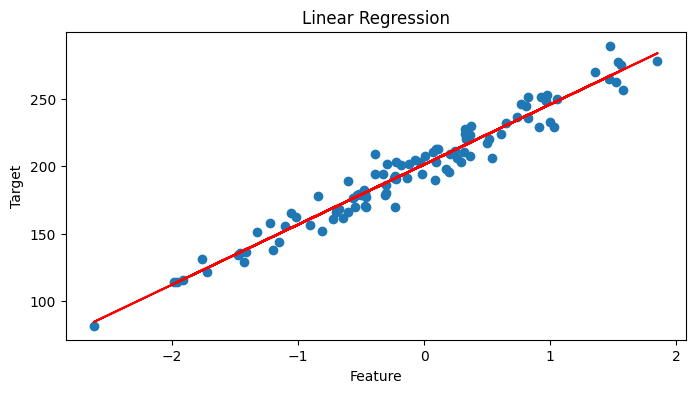

In [9]:
plt.figure(figsize=(8, 4))
plt.scatter(X, y)
plt.plot(X, beta * X + b, color='red')
plt.xlabel('Feature')
plt.ylabel('Target')
plt.title('Linear Regression')
plt.show()

# OLS Implementation

In [10]:
model = LinearRegression()
model.ols(X, y)

print(f"beta: {model.coef_[0]:.3f}, b: {model.intercept_:.3f}")

beta: 44.437, b: 201.165


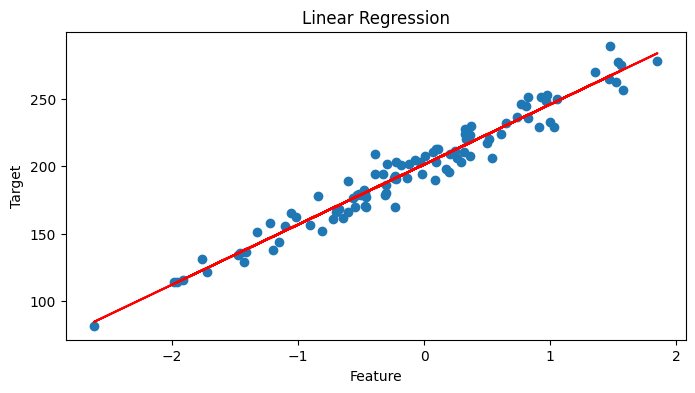

In [11]:
plt.figure(figsize=(8, 4))
plt.scatter(X, y)
plt.plot(X, model.coef_[0] * X + model.intercept_, color='red')
plt.xlabel('Feature')
plt.ylabel('Target')
plt.title('Linear Regression')
plt.show()

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from linear_regression import RidgeRegression, LassoRegression, ElasticNet

Xm, ym = make_regression(n_samples=300, n_features=15, n_informative=5, noise=15.0, random_state=42)
Xm_train, Xm_test, ym_train, ym_test = train_test_split(Xm, ym, test_size=0.25, random_state=42)

m_scaler = StandardScaler()
Xm_train_s = m_scaler.fit_transform(Xm_train)
Xm_test_s = m_scaler.transform(Xm_test)
n = Xm_train_s.shape[0]

In [13]:
from sklearn.linear_model import Ridge

alpha_ridge = 5.0
ridge = RidgeRegression(lambda_=alpha_ridge).ols(Xm_train_s, ym_train)
sk_ridge = Ridge(alpha=alpha_ridge).fit(Xm_train_s, ym_train)

print(f"My Ridge R2:      {r2_score(ym_test, ridge.predict(Xm_test_s)):.4f}")
print(f"sklearn Ridge R2: {r2_score(ym_test, sk_ridge.predict(Xm_test_s)):.4f}")
print(f"Max coef diff:    {np.max(np.abs(ridge.coef_ - sk_ridge.coef_)):.2e}")

My Ridge R2:      0.9854
sklearn Ridge R2: 0.9854
Max coef diff:    2.84e-14


In [14]:
from sklearn.linear_model import Lasso

alpha_lasso = 1.0
lasso = LassoRegression(lambda_=2 * n * alpha_lasso)
lasso.fit(Xm_train_s, ym_train, lr=0.01, max_iter=20000)
sk_lasso = Lasso(alpha=alpha_lasso, max_iter=10000).fit(Xm_train_s, ym_train)

print(f"My Lasso R2:      {r2_score(ym_test, lasso.predict(Xm_test_s)):.4f}")
print(f"sklearn Lasso R2: {r2_score(ym_test, sk_lasso.predict(Xm_test_s)):.4f}")
print(f"Zeroed features -- mine: {np.sum(np.abs(lasso.coef_) < 1e-6)}/15   sklearn: {np.sum(np.abs(sk_lasso.coef_) < 1e-10)}/15")

My Lasso R2:      0.9860
sklearn Lasso R2: 0.9860
Zeroed features -- mine: 8/15   sklearn: 8/15


In [15]:
from sklearn.linear_model import ElasticNet as SkElasticNet

alpha_en, l1_ratio = 0.1, 0.5
en = ElasticNet(l1=2 * n * alpha_en * l1_ratio, l2=n * alpha_en * (1 - l1_ratio))
en.fit(Xm_train_s, ym_train, lr=0.01, max_iter=20000)
sk_en = SkElasticNet(alpha=alpha_en, l1_ratio=l1_ratio, max_iter=10000).fit(Xm_train_s, ym_train)

print(f"My ElasticNet R2:      {r2_score(ym_test, en.predict(Xm_test_s)):.4f}")
print(f"sklearn ElasticNet R2: {r2_score(ym_test, sk_en.predict(Xm_test_s)):.4f}")
print(f"Max coef diff:         {np.max(np.abs(en.coef_ - sk_en.coef_)):.2e}")

My ElasticNet R2:      0.9833
sklearn ElasticNet R2: 0.9833
Max coef diff:         6.16e-04


# LARS Implementation

In [16]:
from sklearn.linear_model import Lars
from linear_regression import LARS

y_mean = ym_train.mean()
lars = LARS().fit(Xm_train_s, ym_train - y_mean)
sk_lars = Lars().fit(Xm_train_s, ym_train)

lars_pred = lars.predict(Xm_test_s) + y_mean
sk_lars_pred = sk_lars.predict(Xm_test_s)

print(f"My LARS R2:      {r2_score(ym_test, lars_pred):.4f}")
print(f"sklearn LARS R2: {r2_score(ym_test, sk_lars_pred):.4f}")
print(f"Max coef diff:   {np.max(np.abs(lars.coef_ - sk_lars.coef_)):.2e}")

My LARS R2:      0.9861
sklearn LARS R2: 0.9859
Max coef diff:   1.32e+00


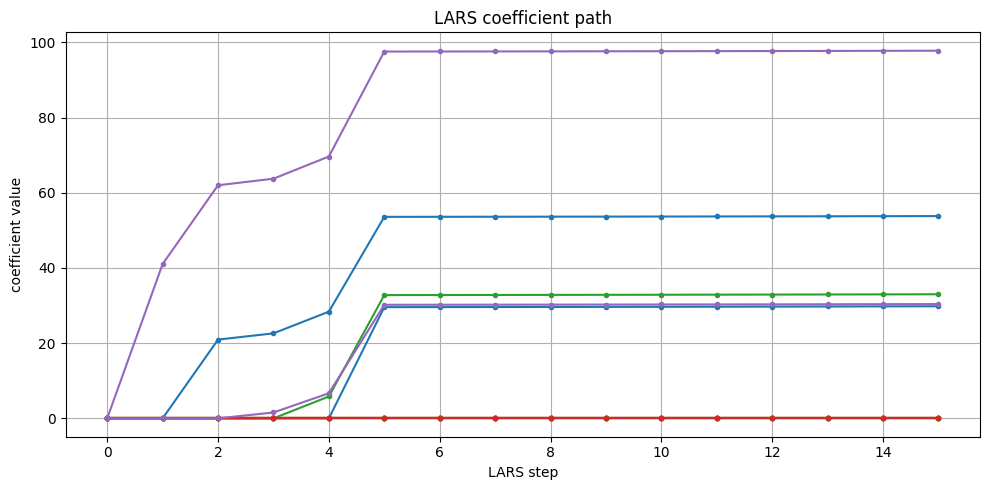

In [17]:
coef_path = np.array(lars.coef_path_)

plt.figure(figsize=(10, 5))
for j in range(coef_path.shape[1]):
    plt.plot(coef_path[:, j], marker='o', markersize=3)
plt.xlabel("LARS step")
plt.ylabel("coefficient value")
plt.title("LARS coefficient path")
plt.grid(zorder=0)
plt.tight_layout()
plt.show()

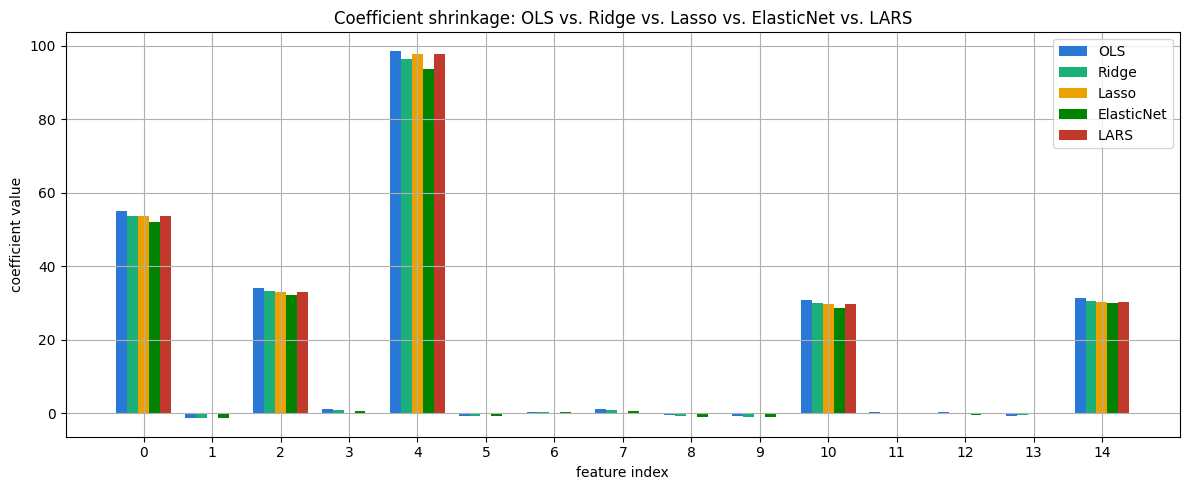

In [18]:
from linear_regression import LinearRegression as LinReg

ols_m = LinReg().ols(Xm_train_s, ym_train)

CATEGORICAL_COLORS = ["#2a78d6", "#1baf7a", "#eda100", "#008300", "#c0392b"]  # fixed order
model_labels = ["OLS", "Ridge", "Lasso", "ElasticNet", "LARS"]
model_coefs = [ols_m.coef_, ridge.coef_, lasso.coef_, en.coef_, lars.coef_]

n_features = Xm.shape[1]
n_models = len(model_labels)
x_pos = np.arange(n_features)
width = 0.16

fig, ax = plt.subplots(figsize=(12, 5))
for i, (label, coef, color) in enumerate(zip(model_labels, model_coefs, CATEGORICAL_COLORS)):
    ax.bar(x_pos + (i - (n_models - 1) / 2) * width, coef, width, label=label, color=color)
ax.set_xlabel("feature index")
ax.set_ylabel("coefficient value")
ax.set_title("Coefficient shrinkage: OLS vs. Ridge vs. Lasso vs. ElasticNet vs. LARS")
ax.set_xticks(x_pos)
ax.grid(zorder=0)
ax.legend()

plt.tight_layout()
plt.show()